<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/JS03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_3258/1805715559.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(value=df['Age'].mean(), inplace=True)
/tmp/ipykernel_3258/1805715559.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True

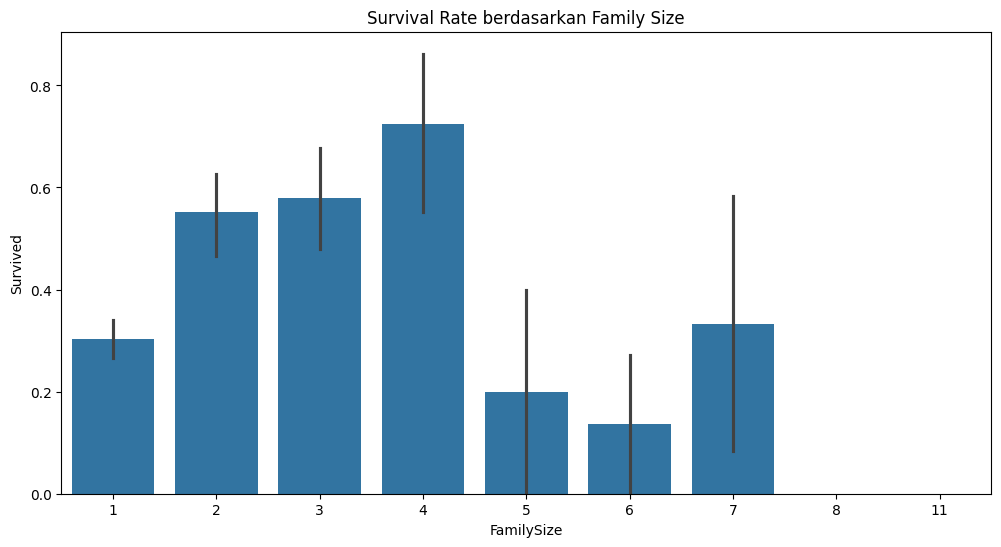

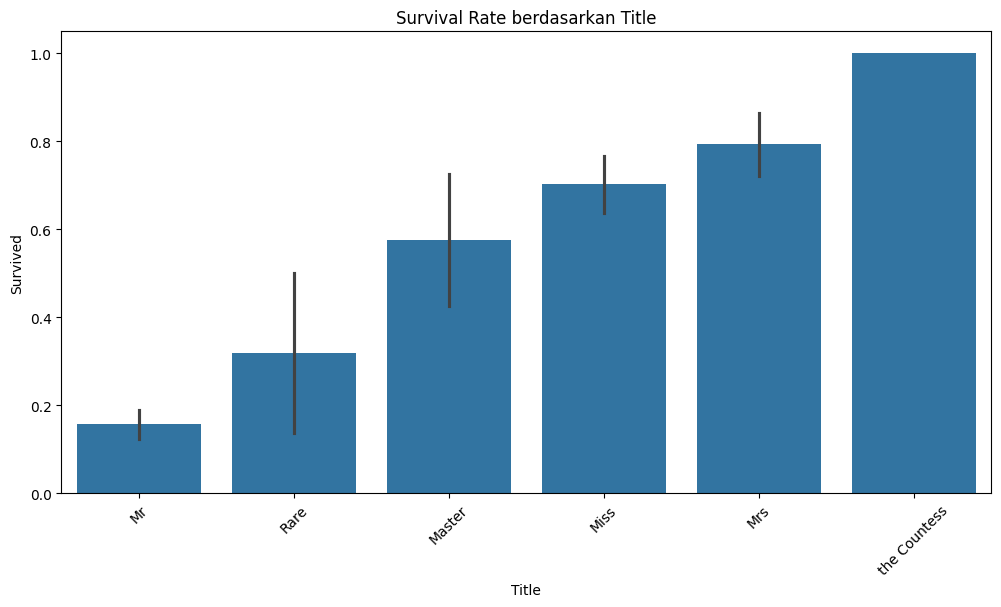

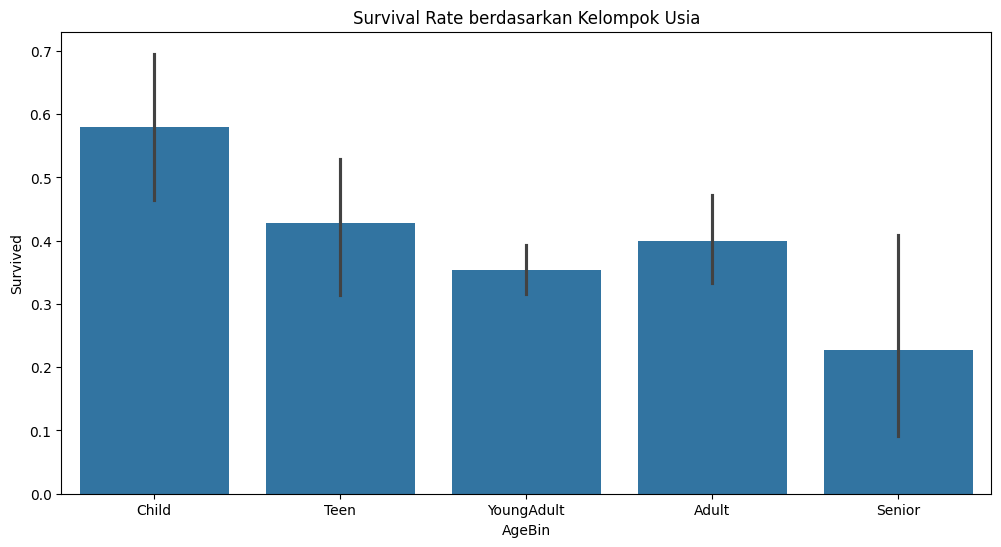

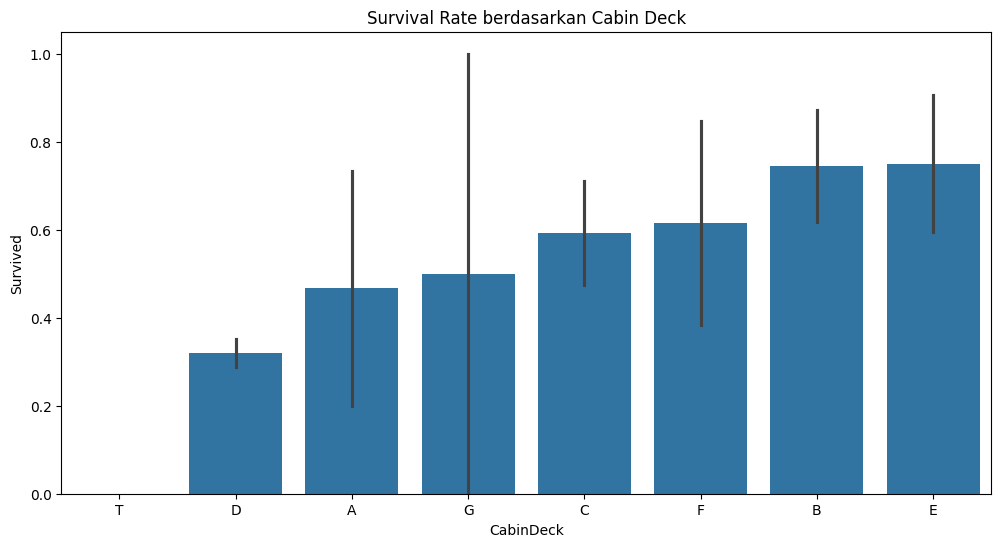

In [1]:
# Praktikum 1
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
dpath = 'Titanic-Dataset.csv'
df = pd.read_csv(dpath)

# Imputasi
df['Age'].fillna(value=df['Age'].mean(), inplace=True)
df['Cabin'].fillna(value="DECK", inplace=True)
df['Embarked'].fillna(value=df['Embarked'].mode, inplace=True)

# Ekstraksi Fitur
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["Title"] = df["Name"].str.extract(r',\s*([^\.]+)\.', expand=False)

title_mapping = {
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Lady": "Rare", "Countess": "Rare", "Capt": "Rare", "Col": "Rare",
    "Don": "Rare", "Dr": "Rare", "Major": "Rare", "Rev": "Rare",
    "Sir": "Rare", "Jonkheer": "Rare", "Dona": "Rare"
}
df["Title"] = df["Title"].replace(title_mapping)
df["AgeBin"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
                      labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"])
df["CabinDeck"] = df["Cabin"].astype(str).str[0]
df["FarePerPerson"] = df["Fare"] / df["FamilySize"]

# Visualisasi Fitur
plt.figure(figsize=(12, 6))
sns.barplot(x="FamilySize", y="Survived", data=df)
plt.title("Survival Rate berdasarkan Family Size")
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x="Title", y="Survived", data=df, order=df.groupby("Title")["Survived"].mean().sort_values().index)
plt.title("Survival Rate berdasarkan Title")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x="AgeBin", y="Survived", data=df, order=["Child", "Teen", "YoungAdult", "Adult", "Senior"])
plt.title("Survival Rate berdasarkan Kelompok Usia")
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x="CabinDeck", y="Survived", data=df, order=df.groupby("CabinDeck")["Survived"].mean().sort_values().index)
plt.title("Survival Rate berdasarkan Cabin Deck")
plt.show()

In [2]:
# Praktikum 2
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Load data
dpath = '/content/Titanic-Dataset-fixed.csv'
df = pd.read_csv(dpath)

# Encoding fitur kategorikal
df['Sex'] = df['Sex'].map({'male': 1, 'female': 0})
df['Cabin'] = df['Cabin'].fillna('Unknown')
df['Cabin'] = df['Cabin'].apply(lambda x: x[0] if x != 'Unknown' else 'U')

# Imputasi nilai kosong pada fitur 'Age' dengan median
df['Age'] = df[['Age']].fillna(df['Age'].median())

# Standarisasi fitur 'Age'
scaler = StandardScaler()
df['Age'] = scaler.fit_transform(df[['Age']])

# Seleksi Fitur
df = df[['Survived', 'Pclass', 'Age', 'Sex', 'Cabin']]
df.head()

,Survived,Pclass,Age,Sex,Cabin
0,0,3,-0.592481,1,D
1,1,1,0.638789,0,C
2,1,3,-0.284663,0,D
3,1,1,0.407926,0,C
4,0,3,0.407926,1,D


In [3]:
# Praktikum 3
import pandas as pd
from sklearn.model_selection import train_test_split, KFold

# 1. Random Split
df = pd.read_csv('Titanic-Dataset-selected.csv')
df_train, df_unseen = train_test_split(df, test_size=0.2, random_state=0)
df_val, df_test = train_test_split(df_unseen, test_size=0.5, random_state=0)

# 2. Stratified Split
df2 = pd.read_csv('Titanic-Dataset-selected.csv')
df2_train, df2_unseen = train_test_split(df2, test_size=0.2, random_state=0, stratify=df['Survived'])
df2_val, df2_test = train_test_split(df2_unseen, test_size=0.5, random_state=0, stratify=df_unseen['Survived'])

# 3. Cross Validation 1 (Split data utuh)
df3 = pd.read_csv('Titanic-Dataset-selected.csv')
kf = KFold(n_splits=4)
for train_index, test_index in kf.split(df3):
    pass # Lakukan sesuatu dengan train_index dan test_index

# 4. Cross Validation 2 (Split data training saja)
df4 = pd.read_csv('Titanic-Dataset-selected.csv')
df4_train, df4_test = train_test_split(df4, test_size=0.2, random_state=0)
kf2 = KFold(n_splits=4)
for train_index, test_index in kf2.split(df4_train):
    pass

In [5]:
# Praktikum 4
!pip install Pillow
from PIL import Image

# Load gambar
img = Image.open('/content/lena.jpg')
img.show()

# Ekstrak setiap channel red, green, blue
r, g, b = img.split()

# Fitur histogram pada channel red
print(len(r.histogram()))
print(r.histogram())

256
[816, 230, 178, 305, 314, 282, 405, 389, 415, 443, 505, 517, 543, 628, 694, 739, 745, 774, 866, 866, 918, 1009, 1029, 1084, 1085, 1173, 1165, 1255, 1218, 1197, 1129, 1219, 1193, 1129, 1142, 1123, 1113, 1101, 1058, 1032, 942, 887, 822, 811, 740, 709, 692, 709, 649, 595, 593, 592, 522, 563, 501, 512, 513, 510, 503, 476, 464, 423, 415, 404, 422, 395, 421, 410, 413, 383, 429, 393, 397, 401, 398, 431, 389, 440, 416, 403, 457, 399, 473, 399, 405, 447, 427, 451, 421, 474, 454, 454, 477, 426, 442, 449, 482, 477, 509, 498, 491, 525, 522, 534, 516, 524, 544, 521, 523, 529, 517, 566, 569, 572, 596, 555, 588, 579, 579, 618, 626, 608, 608, 591, 672, 620, 619, 646, 649, 658, 711, 647, 697, 689, 694, 686, 706, 744, 802, 889, 877, 933, 1019, 1243, 1235, 1143, 1190, 1178, 1259, 1273, 1350, 1202, 1172, 1117, 995, 978, 1002, 960, 895, 948, 1001, 1073, 1122, 1133, 1057, 1179, 1175, 1200, 1165, 1259, 1215, 1306, 1324, 1325, 1367, 1452, 1255, 1362, 1266, 1367, 1389, 1400, 1396, 1552, 1507, 1751, 1711, 1

In [6]:
# Tugas Praktikum
# Import library yang dibutuhkan
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Load dataset
df = pd.read_csv('wbc.csv')

# 1. Memisahkan variabel yang tidak dapat digunakan
# Menghapus kolom 'id' dan kolom kosong 'Unnamed: 32' jika ada
kolom_hapus = ['id']
if 'Unnamed: 32' in df.columns:
    kolom_hapus.append('Unnamed: 32')
df = df.drop(columns=kolom_hapus)

# 2. Encoding pada kolom diagnosis
le = LabelEncoder()
df['diagnosis'] = le.fit_transform(df['diagnosis'])
# Catatan: Malignant (M) menjadi 1, Benign (B) menjadi 0

# Memisahkan fitur (X) dan target (y)
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# 3. Standarisasi pada semua kolom numerik (fitur)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Stratified split data untuk train dan test (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Menampilkan hasil pembagian data untuk verifikasi
print("Total data awal:", len(df))
print("Jumlah data latih (80%):", len(X_train))
print("Jumlah data uji (20%):", len(X_test))

Total data awal: 569
Jumlah data latih (80%): 455
Jumlah data uji (20%): 114
